# Question 1: Convolutional Filters

Convolutional layers are extensively used for image processing and deep learning. These layers work with the help of sliding a small matrix of numbers known as the filter or kernel across the images. After that, the multiplication between the filter and corresponding pixels is performed and their summation results in a new value. This method is used to detect certain patterns in images including edges and textures. For instance, a horizontal edge filter is based on a comparison between the values of pixels at the top and bottom positions making it possible to find regions where the change of brightness occurs between the top and bottom positions.

The output size depends on the input size \(N\), the kernel size \(K\), the stride \(S\) and the padding \(P\) and can be found using the following equation:

$$\text{output size} = \left\lfloor \frac{N + 2P - K}{S} \right\rfloor + 1$$

In this notebook, I use the 64 × 64 grayscale image of coffee from scikit-image dataset for exploration of convolutional filters. The tasks are split into three parts:

1. Refactoring the code:
In the original demo, there is an expression with nine elements for every filter and similar logic is used repeatedly. I use the new convolve2d function and the additional conv_output_size function instead. Then I repeat the four images from the demo and investigate what was done in the original demo. This includes investigating the bug in the original computations.

2. Validating the results:
 I test my implementation by comparing it with torch.nn.functional.conv2d with float64 precision and different parameters for kernel, stride, and padding. The aim is to prove that the two implementations have results almost equal up to (10^{-10}).

3. Testing extra filters:
 I apply Sobel-x, Sobel-y, gradient magnitude, box blur, Gaussian blur, and sharpening filters to the image. Also, I check the pixel variance before and after the filtering to evaluate which filters decrease the variance and which increase the difference between the pixels.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from skimage import data
from skimage.color import rgb2gray
from skimage.transform import resize

torch.manual_seed(0)
np.random.seed(0)

im = resize(rgb2gray(data.coffee()), (64, 64))
print(im.shape)

(64, 64)


## Task 1: Refactor

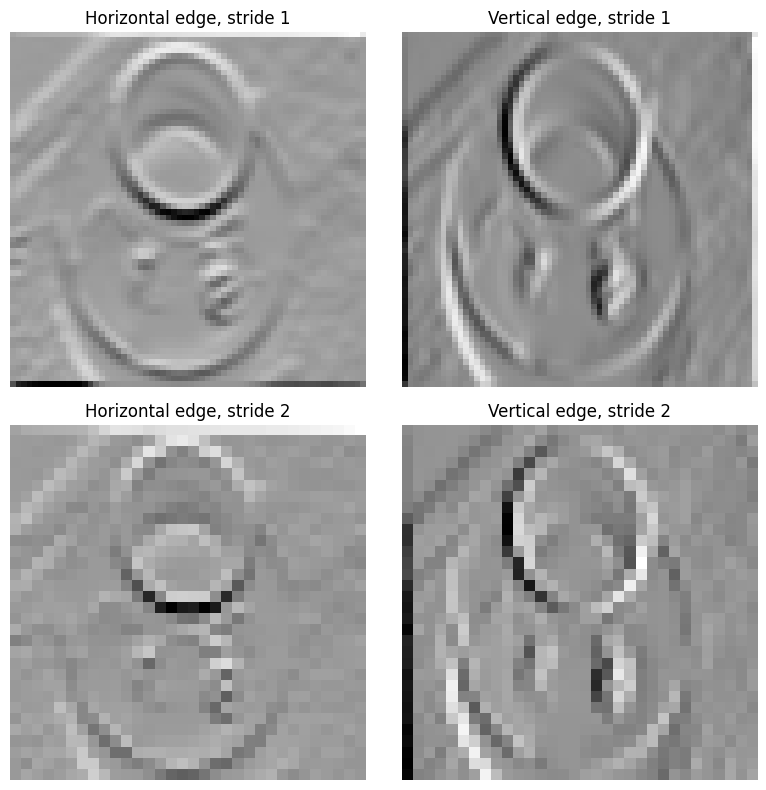

In [2]:
def conv_output_size(N, K, S, P):
    return (N + 2 * P - K) // S + 1


def convolve2d(im, kernel, stride=1, padding=1):
    K = kernel.shape[0]
    im_pad = np.pad(im, padding, "constant")
    n_out = conv_output_size(im.shape[0], K, stride, padding)
    out = np.zeros((n_out, n_out))
    for i in range(n_out):
        for j in range(n_out):
            patch = im_pad[i * stride:i * stride + K, j * stride:j * stride + K]
            out[i, j] = np.sum(patch * kernel)
    return out


Fh = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]])
Fv = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])

results = {
    "Horizontal edge, stride 1": convolve2d(im, Fh, stride=1),
    "Vertical edge, stride 1": convolve2d(im, Fv, stride=1),
    "Horizontal edge, stride 2": convolve2d(im, Fh, stride=2),
    "Vertical edge, stride 2": convolve2d(im, Fv, stride=2),
}

assert results["Horizontal edge, stride 1"].shape == (64, 64)
assert results["Vertical edge, stride 1"].shape == (64, 64)
assert results["Horizontal edge, stride 2"].shape == (32, 32)
assert results["Vertical edge, stride 2"].shape == (32, 32)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for ax, (title, img) in zip(axes.ravel(), results.items()):
    ax.imshow(img, cmap="Greys")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("q1_task1_filters.png", dpi=150)
plt.show()

### Analysis of the demo code

The demo pads the image by one pixel, so image pixel (i, j) is stored at `im_pad[i+1, j+1]`. For output pixel (i, j) it then reads `im_pad[i-1 .. i+1, j-1 .. j+1]`, which is a window centred on image pixel (i-1, j-1) instead of (i, j). The correct window is `im_pad[i:i+3, j:j+3]`. We use the code below to reproduce the demo and compares it with `convolve2d`.

In [3]:
def demo_convolve(im, k, stride=1):
    n = int(im.shape[0] / stride)
    new_image = np.zeros((n, n))
    im_pad = np.pad(im, 1, "constant")
    for i in range(0, im.shape[0], stride):
        for j in range(0, im.shape[1], stride):
            try:
                new_image[int(i / stride), int(j / stride)] = (
                    im_pad[i - 1, j - 1] * k[0, 0] + im_pad[i - 1, j] * k[0, 1] + im_pad[i - 1, j + 1] * k[0, 2]
                    + im_pad[i, j - 1] * k[1, 0] + im_pad[i, j] * k[1, 1] + im_pad[i, j + 1] * k[1, 2]
                    + im_pad[i + 1, j - 1] * k[2, 0] + im_pad[i + 1, j] * k[2, 1] + im_pad[i + 1, j + 1] * k[2, 2]
                )
            except:
                pass
    return new_image


for name, k in [("horizontal", Fh), ("vertical", Fv)]:
    for s in (1, 2):
        d = demo_convolve(im, k, s)
        m = convolve2d(im, k, s, 1)
        print(f"{name}, stride {s}: max |demo - mine| = {np.abs(d - m).max():.3f}, "
              f"mean = {np.abs(d - m).mean():.3f}, relative L2 error = {np.linalg.norm(d - m) / np.linalg.norm(m):.3f}")

for name, k in [("horizontal", Fh), ("vertical", Fv)]:
    full = convolve2d(im, k, stride=1, padding=2)
    d1 = demo_convolve(im, k, 1)
    d2 = demo_convolve(im, k, 2)
    m1 = convolve2d(im, k, 1, 1)
    print(name, "| demo == conv(padding=2)[:64, :64]:", np.allclose(d1, full[:64, :64]),
          "| demo[1:, 1:] == mine[:-1, :-1]:", np.allclose(d1[1:, 1:], m1[:-1, :-1]),
          "| stride 2 demo == conv(padding=2)[:64:2, :64:2]:", np.allclose(d2, full[:64:2, :64:2]))

horizontal, stride 1: max |demo - mine| = 2.551, mean = 0.183, relative L2 error = 0.972
horizontal, stride 2: max |demo - mine| = 2.508, mean = 0.156, relative L2 error = 0.809
vertical, stride 1: max |demo - mine| = 2.358, mean = 0.224, relative L2 error = 0.941
vertical, stride 2: max |demo - mine| = 2.194, mean = 0.192, relative L2 error = 0.792
horizontal | demo == conv(padding=2)[:64, :64]: True | demo[1:, 1:] == mine[:-1, :-1]: True | stride 2 demo == conv(padding=2)[:64:2, :64:2]: True
vertical | demo == conv(padding=2)[:64, :64]: True | demo[1:, 1:] == mine[:-1, :-1]: True | stride 2 demo == conv(padding=2)[:64:2, :64:2]: True


Analysis of the Demo Output

This implementation will not give the same output as a zero-padded convolution. In this case, the problem lies in the way that the image is accessed after it has been padded. With stride equal to 1, there is a shift of one pixel both down and to the right in comparison to my implementation. This has been confirmed with `demo[1:, 1:] == mine[:-1, :-1]`. In addition to that, the demo provides the same output as if you take the top-left part of size \(64 \times 64\) of a convolution with padding 2.

The relative error for the stride of 1 is close to 0.97, which means that the two outputs have a considerable difference in pixel values, although the overall images seem similar. In case the stride equals 2, the demo uses different coordinates to apply the filter, which are \((2m-1, 2n-1)\), not \((2m, 2n)\). As a consequence, different locations of the image are being used to calculate the output.

The `try/except` construction cannot catch this error since Python supports negative indexing. Hence, when `i = 0` or `j = 0`, `-1` is interpreted as the last row or column of the padded array.
Since the array already contains zero padding, the code runs without raising an exception, making the indexing problem harder to detect.

## Task 2: Validate

In [4]:
def torch_conv(im, kernel, stride, padding):
    x = torch.from_numpy(im).double()[None, None]
    w = torch.from_numpy(np.asarray(kernel)).double()[None, None]
    return F.conv2d(x, w, stride=stride, padding=padding)[0, 0].numpy()


box5 = np.ones((5, 5)) / 25
kernels = {"Fh": Fh, "Fv": Fv, "box 5x5": box5}

print(f"{'kernel':<9}{'stride':>7}{'padding':>9}{'shape':>10}{'max diff':>12}")
worst = 0
for name, k in kernels.items():
    for s in (1, 2):
        for p in (0, 1, 2):
            mine = convolve2d(im, k, stride=s, padding=p)
            ref = torch_conv(im, k, s, p)
            assert mine.shape == ref.shape
            diff = np.abs(mine - ref).max()
            worst = max(worst, diff)
            assert diff < 1e-10
            print(f"{name:<9}{s:>7}{p:>9}{str(mine.shape):>10}{diff:>12.2e}")
print("largest difference:", worst)

kernel    stride  padding     shape    max diff
Fh             1        0  (62, 62)    4.44e-16
Fh             1        1  (64, 64)    4.44e-16
Fh             1        2  (66, 66)    4.44e-16
Fh             2        0  (31, 31)    4.44e-16
Fh             2        1  (32, 32)    4.44e-16
Fh             2        2  (33, 33)    4.44e-16
Fv             1        0  (62, 62)    4.44e-16
Fv             1        1  (64, 64)    4.44e-16
Fv             1        2  (66, 66)    4.44e-16
Fv             2        0  (31, 31)    4.44e-16
Fv             2        1  (32, 32)    2.22e-16
Fv             2        2  (33, 33)    4.44e-16
box 5x5        1        0  (60, 60)    3.33e-16
box 5x5        1        1  (62, 62)    3.33e-16
box 5x5        1        2  (64, 64)    3.33e-16
box 5x5        2        0  (30, 30)    3.33e-16
box 5x5        2        1  (31, 31)    2.22e-16
box 5x5        2        2  (32, 32)    3.33e-16
largest difference: 4.440892098500626e-16


### Evaluation of PyTorch Convolution Test

All the 18 test cases generated the same output shapes as that from PyTorch, with the maximum difference in the generated outputs well below \(10^{-10}\). This implies that the `convolve2d` function performs correctly in the tested filter types, stride parameters, and padding.

To further confirm the convolution implementation in both the cases, I compared how the kernels are convoluted with the image. Both do not flip the kernel, but instead directly multiply the kernel with the image patches. This confirms that my implementation is similar to that of PyTorch's `Conv2d`.

## Task 3: More filters

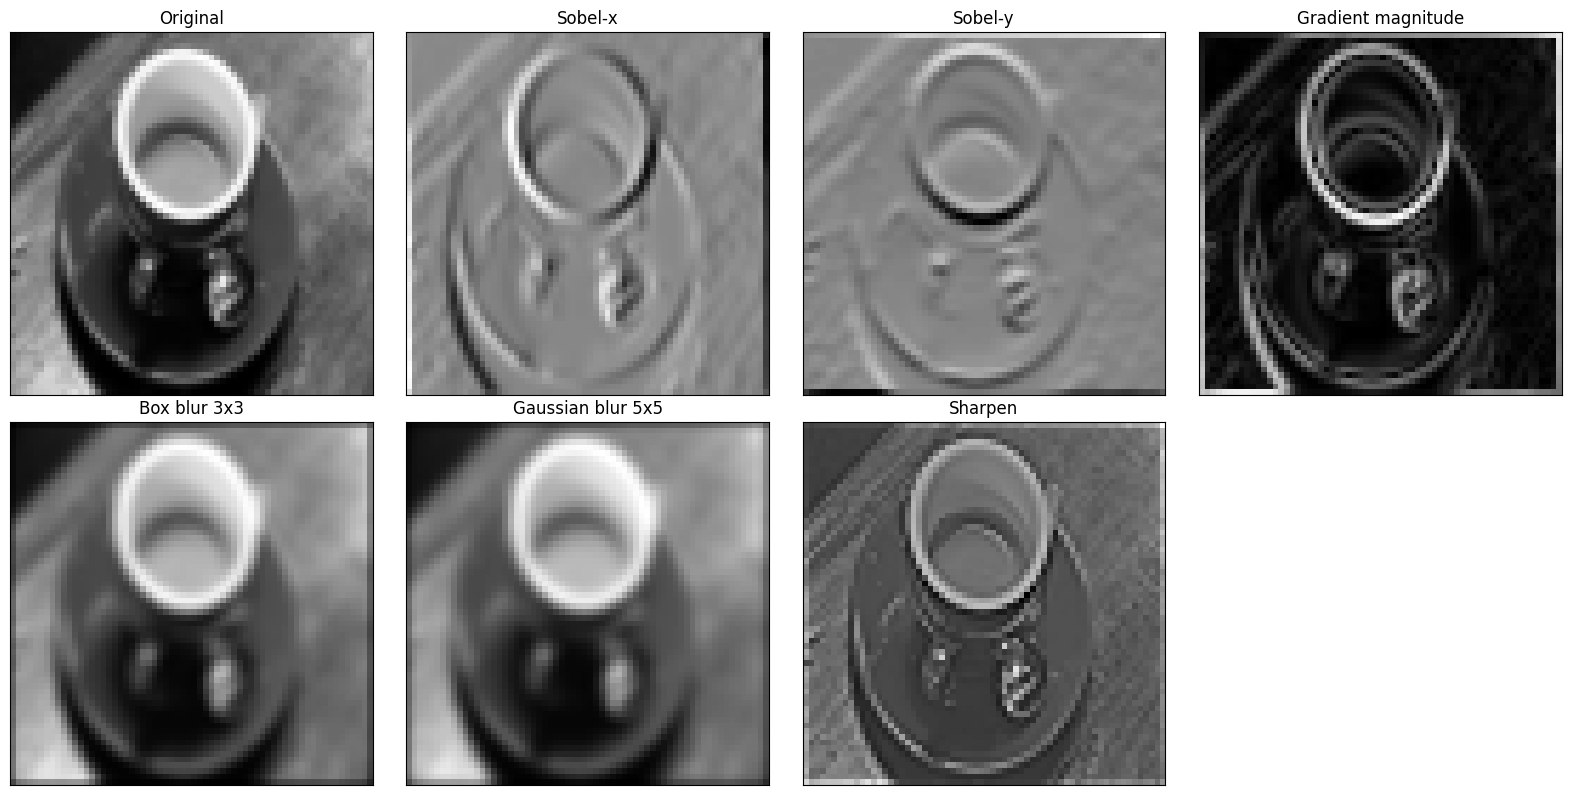

image                 variance  smaller than input
Input                   0.0460
Sobel-x                 0.3516               False
Sobel-y                 0.2610               False
Gradient magnitude      0.3634               False
Box blur 3x3            0.0399                True
Gaussian blur 5x5       0.0382                True
Sharpen                 0.1095               False


In [5]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
box3 = np.ones((3, 3)) / 9
g = np.array([1, 4, 6, 4, 1])
gauss5 = np.outer(g, g) / 256
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

Gx = convolve2d(im, sobel_x, 1, 1)
Gy = convolve2d(im, sobel_y, 1, 1)

more = {
    "Sobel-x": Gx,
    "Sobel-y": Gy,
    "Gradient magnitude": np.sqrt(Gx ** 2 + Gy ** 2),
    "Box blur 3x3": convolve2d(im, box3, 1, 1),
    "Gaussian blur 5x5": convolve2d(im, gauss5, 1, 2),
    "Sharpen": convolve2d(im, sharpen, 1, 1),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes[0, 0].imshow(im, cmap="gray")
axes[0, 0].set_title("Original")
for ax, (name, out) in zip(axes.ravel()[1:], more.items()):
    ax.imshow(out, cmap="gray")
    ax.set_title(name)
axes[1, 3].axis("off")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig("q1_task3_filters.png", dpi=150)
plt.show()

print(f"{'image':<20}{'variance':>10}{'smaller than input':>20}")
print(f"{'Input':<20}{im.var():>10.4f}")
for name, out in more.items():
    print(f"{name:<20}{out.var():>10.4f}{str(out.var() < im.var()):>20}")

### Analysis

The 3 × 3 box blur and the 5 × 5 Gaussian blur are the only filters that produce a smaller pixel variance than the original image. Their variances are about 0.040 and 0.038, compared with 0.046 for the input image. Both filters calculate a weighted average of nearby pixels using non-negative weights that sum to 1. This smooths out local intensity differences and makes the pixel values more similar to each other.

The other filters produce higher variances. Sobel-x, Sobel-y, and the gradient magnitude highlight changes in image intensity, which makes their output values vary more. Their variances are about 0.35, 0.26, and 0.36, respectively. The sharpening filter also increases variance to about 0.11 because it emphasizes differences between neighboring pixels, making edges and fine details more pronounced.